# THUNDER4D tutorial

*Transverse-resolved Herriott-cell UPPE solver for Nonlinear Dynamics close to Experimental Reality, 4D*

This notebook walks through the code step by step, from the gas to a full multipass-cell simulation, using the **lens-frame solver** (`LensFrameSimulation`), whose grid follows the beam inside the cell:

1. setup and device (CPU or GPU)
2. the nonlinear medium
3. the cell: geometry, eigenmode, nonlinear mode matching
4. the lens frame and the grid
5. the pulse: spectrum, spatial profiles (incl. Laguerre–Gauss), aberrations, space-time couplings
6. injecting the beam into the cell
7. running a simulation
8. analysing the results (cell centre, collimated beam, mirrors)
9. saving, checkpoints, and running on a GPU

Every simulation here uses a small near-concentric test cell so that the whole notebook runs in a few minutes on a laptop CPU. Change the parameters freely: each section is self-contained once the cells above it have run.

## 1. Setup and device

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

import thunder4d as th
from thunder4d import diagnostics as dg

DEVICE = "auto"      # "auto" = GPU if CuPy works, else CPU; or force "cpu" / "gpu"
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 3.4)})
print("thunder4d", th.__version__, "| GPU available:", th.gpu_available())

thunder4d 0.10.0 | GPU available: False


## 2. The nonlinear medium

`Material` gives the refractive index (Sellmeier formula of Börzsönyi *et al.* 2008) and the nonlinear index $n_2$, both scaled with pressure. `critical_power` is the Gaussian-beam self-focusing power $P_c = \lambda^2/(2\pi n_0 n_2)$.

In [2]:
for p_bar in (0.5, 1.0, 5.0):
    gas = th.Material("Ar", pressure_bar=p_bar)
    lam = 1030e-9
    w = 2 * np.pi * th.C0 / lam
    print(f"Ar {p_bar:3.1f} bar: n-1 = {gas.n(w)-1:.3e}, n2 = {gas.n2:.2e} m^2/W, "
          f"GVD = {gas.gvd(lam):5.1f} fs^2/m, Pc = {gas.critical_power(lam)/1e9:5.2f} GW")

gas = th.Material("Ar", 1.0, n2_1bar=1.0e-23)

Ar 0.5 bar: n-1 = 1.282e-04, n2 = 5.00e-24 m^2/W, GVD =   7.0 fs^2/m, Pc = 33.77 GW
Ar 1.0 bar: n-1 = 2.565e-04, n2 = 1.00e-23 m^2/W, GVD =  13.9 fs^2/m, Pc = 16.88 GW
Ar 5.0 bar: n-1 = 1.282e-03, n2 = 5.00e-23 m^2/W, GVD =  69.4 fs^2/m, Pc =  3.37 GW


## 3. The multipass cell

### Geometry
`MPC.herriott(R, N, k, ...)` builds a re-entrant Herriott cell that closes on itself after N passes. Two mirror separations give the same spot pattern: **near-concentric** $d = R[1+\cos(2\pi k/N)]$ (default, usual for high energy) and **near-planar** $d = R[1-\cos(2\pi k/N)]$. Any separation can also be given directly with `MPC(R, d, medium, n_passes)`.

In [3]:
for branch in ("concentric", "planar"):
    c = th.MPC.herriott(R=2.0, N=30, k=2, medium=gas, branch=branch)
    m = c.linear_mode(1030e-9)
    print(f"{branch:10s}: d = {c.d:.3f} m, Gouy phase/pass = {np.degrees(c.theta):5.1f} deg, "
          f"waist {m['w0']*1e6:.0f} um, mirror spot {m['w_mirror']*1e6:.0f} um")

concentric: d = 3.827 m, Gouy phase/pass = 156.0 deg, waist 365 um, mirror spot 1756 um
planar    : d = 0.173 m, Gouy phase/pass =  24.0 deg, waist 365 um, mirror spot 373 um


For this tutorial we use a small near-concentric cell (R = 0.5 m, d ≈ 0.98 m) and simulate 10 of its passes. Near-concentric cells have a tiny waist and a large spot on the mirrors: that is exactly the case the lens frame (section 4) is made for.

### Eigenmode and nonlinear mode matching
The Kerr lens of the gas shrinks the stationary beam of the cell. In the aberration-free model a Gaussian beam of power $P$ behaves like a linear beam of wavelength $\lambda\sqrt{1-P/P_c}$, so the matched waist and mirror spot scale as $(1-P/P_c)^{1/4}$ (Hanna *et al.*, JOSA B 2017; OSA Continuum 2021).

In [4]:
cell = th.MPC.herriott(R=0.5, N=20, k=1, medium=gas, branch="concentric", n_passes=10)
print(cell.report())

Pc = gas.critical_power(1030e-9)
for r in (0.0, 0.2, 0.4, 0.6):
    m = cell.nonlinear_mode(max(r, 1e-6) * Pc, 1030e-9)
    print(f"P/Pc = {r:.1f}: matched waist {m['w0']*1e6:5.1f} um, mirror {m['w_mirror']*1e6:5.1f} um, "
          f"B/pass ~ {m['B_per_pass']:.2f} rad")

MPC: R = 0.500 m, d = 0.9755 m, 10 passes, Gouy/pass = 162.00 deg, Material(Ar, 1.0 bar, n2 = 1e-23 m^2/W)
P/Pc = 0.0: matched waist 159.1 um, mirror 1017.2 um, B/pass ~ 0.00 rad
P/Pc = 0.2: matched waist 150.5 um, mirror 962.0 um, B/pass ~ 1.26 rad
P/Pc = 0.4: matched waist 140.1 um, mirror 895.3 um, B/pass ~ 2.92 rad
P/Pc = 0.6: matched waist 126.6 um, mirror 809.0 um, B/pass ~ 5.36 rad


## 4. The lens frame and the grid

Inside the cell the beam expands from the waist (cell centre) to the mirrors by the factor $s(z) = \sqrt{1 + z^2/z_R^2}$, where $z_R = \sqrt{d(2R-d)}/2$ is the Rayleigh range of the cell eigenmode. A fixed grid would have to hold the beam on the mirror *and* resolve it at the waist. The lens-frame solver instead writes the field as

$$A(x, y, z) = \frac{1}{s}\, B\!\left(\frac{x}{s}, \frac{y}{s}, \zeta\right) e^{\,i k r^2 / 2R(z)}, \qquad \zeta = z_R \arctan(z/z_R),$$

and propagates $B$ in $\zeta$. In this frame the eigenmode does not change size, the curved mirror is the identity (its curvature cancels the wavefront exactly), and the Kerr term keeps its usual form. So the grid only has to hold the beam **at the waist scale**, whatever the separation.

* At the **cell centre** ($s = 1$) $B$ is the physical field: everything recorded there is physical.
* At the **mirror** the grid is scaled by `s_m` (`sim.mirror_scale`): physical $x = s_m\,\xi$, physical fluence $= F_\text{frame}/s_m^2$.

zR = 7.7 cm, zeta at the mirror = 10.9 cm, mirror scale s_m = 6.39
waist 159 um, mirror spot 1017 um (= s_m x waist)


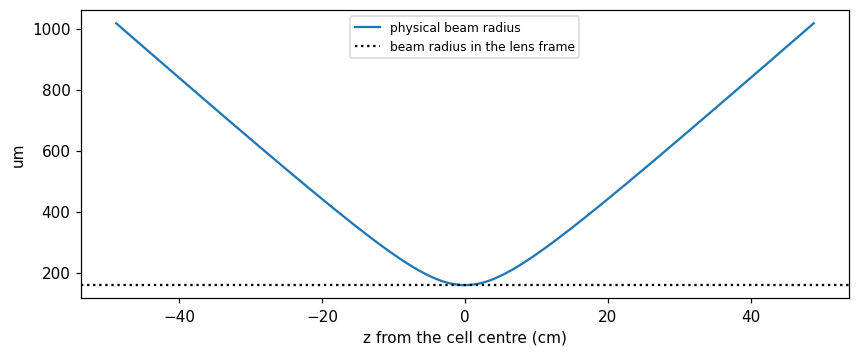

In [5]:
zR, zeta_m, s_m = th.lens_frame_scale(cell)
lin = cell.linear_mode(1030e-9)
print(f"zR = {zR*100:.1f} cm, zeta at the mirror = {zeta_m*100:.1f} cm, mirror scale s_m = {s_m:.2f}")
print(f"waist {lin['w0']*1e6:.0f} um, mirror spot {lin['w_mirror']*1e6:.0f} um (= s_m x waist)")

z = np.linspace(-cell.d / 2, cell.d / 2, 201)
plt.plot(z * 100, lin["w0"] * np.sqrt(1 + (z / zR) ** 2) * 1e6, label="physical beam radius")
plt.axhline(lin["w0"] * 1e6, color="k", ls=":", label="beam radius in the lens frame")
plt.xlabel("z from the cell centre (cm)"); plt.ylabel("um"); plt.legend(fontsize=8);

`suggest_lens_grid` sizes the box from the waist at `lambda_max` (`box_factor` ≈ 6 for matched Gaussians, 10–14 for top-hats, hard edges or strong mismatch), the transverse step from the waist at `lambda_min` (`points_per_waist`), and the time step from the spectral window.

**Conventions** (worth remembering):
* the field `Aw` has shape `(Nx, Ny, Nt)` and lives in the mixed domain $(x, y, \Omega)$;
* all arrays are in **FFT order** (index 0 is $x=0$, $t=0$, $\Omega=0$); use the sorted versions `grid.xs`, `grid.ts`, `grid.lams` for plotting. All `diagnostics` functions already return sorted axes;
* $|A|^2$ is the intensity in W/m²; positive GDD is an up-chirp;
* **far field** = the cell centre (focus, where the field is stored and recorded); **near field** = the collimated beam, i.e. the angular spectrum of the cell-centre field ($x_\mathrm{out} = f\,\theta$ after a collimating lens of focal length $f$).

In [6]:
grid = th.suggest_lens_grid(cell, lambda0=1030e-9, lambda_min=900e-9, lambda_max=1200e-9,
                            pulse_fwhm=200e-15, box_factor=12, device=DEVICE)
print(grid.describe())
print(f"box = {grid.Nx*grid.dx/lin['w0']:.0f} waists; a fixed grid would need ~8 mirror-spot radii, "
      f"i.e. {8*lin['w_mirror']*1e3:.1f} mm, with the same dx")
print("x (FFT order), first values [um]:", np.round(grid.x[:4] * 1e6, 1))
print("x sorted, first values [um]:     ", np.round(grid.xs[:4] * 1e6, 1))

Grid 120x120x144 (17 MB per field, cpu/scipy) | box 2.06 x 2.06 mm, dx = 17.2 um | T = 1689 fs, dt = 11.73 fs | lambda window 900-1207 nm
box = 13 waists; a fixed grid would need ~8 mirror-spot radii, i.e. 8.1 mm, with the same dx
x (FFT order), first values [um]: [ 0.  17.2 34.4 51.5]
x sorted, first values [um]:      [-1030.6 -1013.4  -996.2  -979. ]


## 5. The pulse

A pulse is $A(x, y, \Omega) = E(\Omega)\,U(x, y;\Omega)$: a 1D spectral amplitude times a spatial field (which may depend on the colour). Pulses are defined at the cell centre, where the lens-frame field is the physical one.

### 5.1 Spectrum and spectral phase

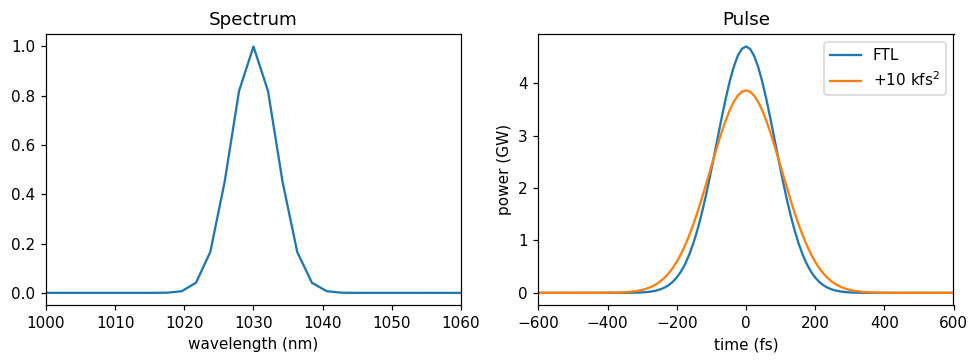

In [7]:
E_tl = th.gaussian_spectrum(grid, fwhm_fs=200)
E_ch = th.add_spectral_phase(grid, E_tl, gdd_fs2=10000, tod_fs3=0)
# other options: th.measured_spectrum(grid, wl_nm, I, phase_rad=...), th.spectrum_from_temporal_field(...)

i = np.argsort(grid.lam)
fig, ax = plt.subplots(1, 2)
ax[0].plot(grid.lam[i] * 1e9, np.abs(E_tl[i]) ** 2 / np.abs(E_tl).max() ** 2)
ax[0].set_xlim(1000, 1060); ax[0].set_xlabel("wavelength (nm)"); ax[0].set_title("Spectrum")
for E, lab in ((E_tl, "FTL"), (E_ch, "+10 kfs$^2$")):
    p = th.Pulse.at_focus(grid, E, th.Beam(th.gaussian(lin["w0"])), 1e-3)
    t, P = dg.temporal_power(grid, p.Aw)
    ax[1].plot(t * 1e15, P / 1e9, label=lab)
ax[1].set_xlim(-600, 600); ax[1].set_xlabel("time (fs)"); ax[1].set_ylabel("power (GW)"); ax[1].set_title("Pulse"); ax[1].legend()
plt.tight_layout()

### 5.2 Spatial profiles
A `Profile` is just a function of $(X, Y)$. Laguerre–Gauss and Hermite–Gauss modes are normalised, so the squared amplitudes of a `mode_superposition` are power fractions.

[Text(1, -3.141592653589793, '$-\\pi$'),
 Text(1, 0.0, '0'),
 Text(1, 3.141592653589793, '$\\pi$')]

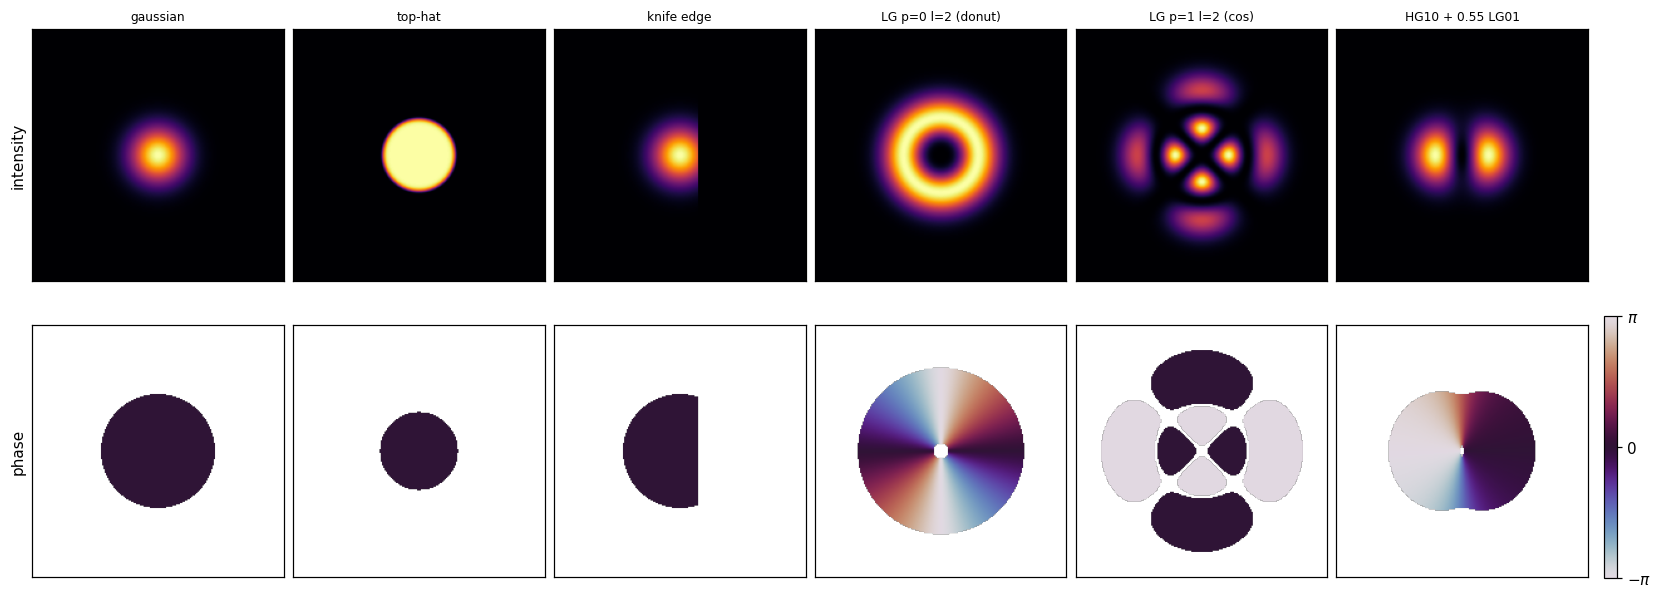

In [8]:
w = 300e-6
profiles = {
    "gaussian": th.gaussian(w),
    "top-hat": th.top_hat(w),
    "knife edge": th.knife_edge(th.gaussian(w), 0.5 * w, axis="x", side="+"),
    "LG p=0 l=2 (donut)": th.laguerre_gauss(w, p=0, l=2),
    "LG p=1 l=2 (cos)": th.laguerre_gauss(w, p=1, l=2, kind="cos"),
    "HG10 + 0.55 LG01": th.mode_superposition([(1.0, th.hermite_gauss(w, 1, 0)),
                                               (0.55, th.laguerre_gauss(w, 0, 1))]),
}
x = np.linspace(-1e-3, 1e-3, 201)
X, Y = x[:, None], x[None, :]
fig, axs = plt.subplots(2, len(profiles), figsize=(15, 5.4), layout="constrained")
for (a_int, a_ph), (name, prof) in zip(axs.T, profiles.items()):
    U = prof(X, Y)
    I = np.abs(U) ** 2
    a_int.imshow(I.T, origin="lower", extent=[-1, 1, -1, 1], cmap="inferno")
    a_int.set_title(name, fontsize=8)
    # phase only where there is light (< 1% of the peak intensity is masked)
    ph = np.ma.masked_where(I < 1e-2 * I.max(), np.angle(U))
    im = a_ph.imshow(ph.T, origin="lower", extent=[-1, 1, -1, 1], cmap="twilight",
                     vmin=-np.pi, vmax=np.pi)
    for a in (a_int, a_ph):
        a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel("intensity"); axs[1, 0].set_ylabel("phase")
fig.colorbar(im, ax=axs, ticks=[-np.pi, 0, np.pi], shrink=0.45, anchor=(0, 0.05), pad=0.01).ax.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])

### 5.3 Aberrations and space-time couplings
A `Beam` combines a profile with Zernike aberrations (RMS waves at $\lambda_0$, applied as an achromatic wavefront) and space-time couplings: spatial chirp, angular dispersion, pulse-front tilt and curvature, radial GDD, or any custom phase. `chromatic_size` makes the spot size scale with wavelength like the cell eigenmode (`"eigenmode"`) or a focused beam (`"focus"`).

Here a spatial chirp of 0.01 mm/nm shows up directly in the spatio-spectral trace $S(x,\lambda)$:

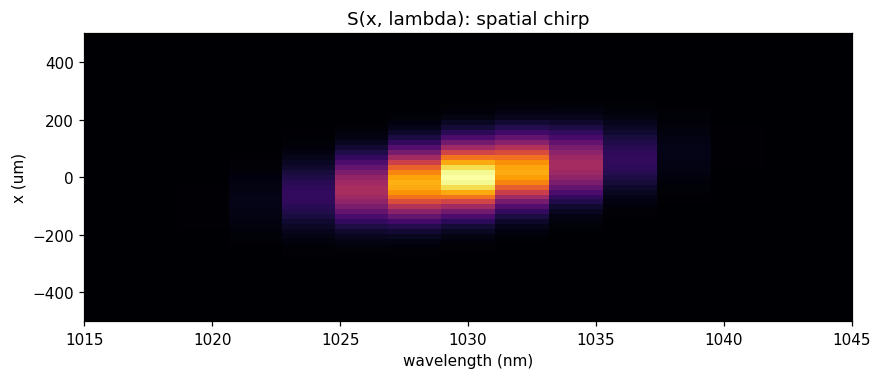

In [9]:
beam = th.Beam(th.gaussian(lin["w0"]), spatial_chirp_mm_per_nm=(0.01, 0.0),
               zernike={"astig_0": 0.05}, pupil_radius=2 * lin["w0"])
p = th.Pulse.at_focus(grid, E_tl, beam, 1e-3)
xs, lam, S = dg.spectrogram_x_lambda(grid, p.Aw)
plt.pcolormesh(lam * 1e9, xs * 1e6, S / S.max(), shading="auto", cmap="inferno")
plt.xlim(1015, 1045); plt.ylim(-500, 500)
plt.xlabel("wavelength (nm)"); plt.ylabel("x (um)"); plt.title("S(x, lambda): spatial chirp");

## 6. Injecting the beam into the cell

The simulation starts at the cell centre. Three builders define where your beam is specified:

| builder | beam defined | typical use |
|---|---|---|
| `Pulse.at_focus` | at the cell centre | ideal matched Gaussian |
| `Pulse.from_near_field` | collimated near field, focused by a lens (exact per-colour Fourier transform) | top-hat near field → Airy pattern at the centre |
| `imaged_near_field_lens` | near field imaged onto the mirror (physical size), then propagated back in the lens frame | flat-top on the input mirror |

For `imaged_near_field_lens` the profile is given in **physical** coordinates at the image plane (here the mirror, so it is sized from `w_mirror`); in the frame it is simply rescaled by $s$.

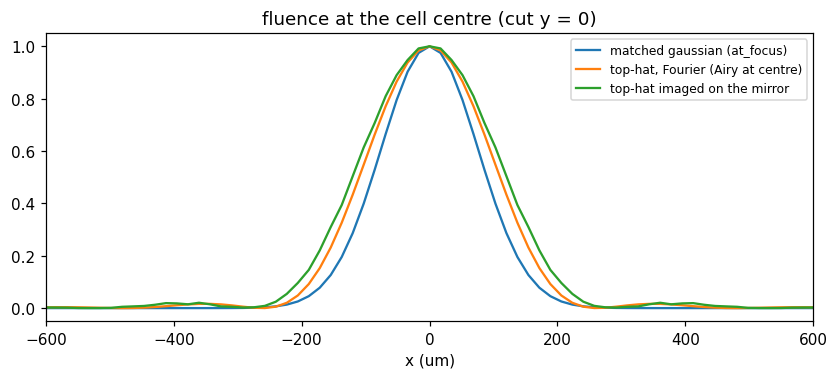

In [10]:
probe = th.Pulse.at_focus(grid, E_tl, th.Beam(th.gaussian(lin["w0"])), 0.6e-3)
mm = cell.match(probe, verbose=False)

inputs = {
    "matched gaussian (at_focus)": th.Pulse.at_focus(
        grid, E_tl, th.Beam(profile=th.gaussian(mm["w0"]), chromatic_size="eigenmode"), energy=0.6e-3),
    "top-hat, Fourier (Airy at centre)": th.Pulse.from_near_field(
        grid, E_tl, th.Beam(profile=th.top_hat(4e-3)), energy=0.6e-3, nf_size=12e-3, nf_points=160,
        target_waist=mm["w0"], verbose=False),
    "top-hat imaged on the mirror": th.imaged_near_field_lens(
        grid, E_tl, th.Beam(profile=th.top_hat(1.12 * mm["w_mirror"])), energy=0.6e-3, cell=cell, verbose=False),
}
for name, p in inputs.items():
    F = dg.fluence(grid, p.Aw)
    plt.plot(grid.xs * 1e6, F[:, grid.Ny // 2] / F.max(), label=name)
plt.xlim(-600, 600); plt.xlabel("x (um)"); plt.title("fluence at the cell centre (cut y = 0)"); plt.legend(fontsize=8);

## 7. Running a simulation

`LensFrameSimulation` propagates pass by pass (centre → mirror → centre) and records diagnostics after every pass. `profile_wavelengths` adds 1D beam profiles of selected colours (bandpass `profile_bandwidth`) at the cell centre (far field), at the mirror and in the collimated beam (near field).

Two numerical parameters set the step in $\zeta$: `phi_max` (peak nonlinear phase per step, controls accuracy: halve it to check convergence) and `gouy_step` (maximum Gouy phase per step, 0.05 rad by default, controls diffraction accuracy).

In [11]:
pulse = inputs["top-hat, Fourier (Airy at centre)"]
sim = th.LensFrameSimulation(pulse, cell, phi_max=0.02, gouy_step=0.05, mode_reference=mm["w0"],
                             profile_wavelengths=[1015e-9, 1030e-9, 1045e-9], profile_bandwidth=2e-9)
t0 = time.time()
sim.run()                       # all passes; sim.run(n_passes=1) to go step by step
print(f"{cell.n_passes} passes in {time.time() - t0:.0f} s")

pass   1/10 | B =   1.13 rad | E = 0.5979 mJ | eta00 = 0.8652 | V_far = 0.9998 | steps 68 | 17 s


pass   2/10 | B =   2.24 rad | E = 0.5976 mJ | eta00 = 0.8628 | V_far = 0.9992 | steps 135 | 33 s


pass   3/10 | B =   3.31 rad | E = 0.5972 mJ | eta00 = 0.8592 | V_far = 0.9985 | steps 201 | 49 s


pass   4/10 | B =   4.29 rad | E = 0.5966 mJ | eta00 = 0.8640 | V_far = 0.9981 | steps 263 | 63 s


pass   5/10 | B =   5.36 rad | E = 0.596 mJ | eta00 = 0.8671 | V_far = 0.9951 | steps 329 | 79 s


...

pass   7/10 | B =   7.53 rad | E = 0.5954 mJ | eta00 = 0.8608 | V_far = 0.9905 | steps 461 | 112 s


pass   8/10 | B =   8.56 rad | E = 0.5953 mJ | eta00 = 0.8578 | V_far = 0.9862 | steps 526 | 129 s


pass   9/10 | B =   9.61 rad | E = 0.5951 mJ | eta00 = 0.8595 | V_far = 0.9817 | steps 591 | 145 s


pass  10/10 | B =  10.68 rad | E = 0.5948 mJ | eta00 = 0.8617 | V_far = 0.9775 | steps 656 | 162 s


10 passes in 162 s


## 8. Analysing the results

### 8.1 Per-pass history

recorded keys: B, M2x, M2x_mean, M2y, M2y_mean, V_far, V_near, band_energy, energy, eta00, eta00_total, fluence, fluence_mirror, order_frac, pass, peak_power, prof_far, prof_far_proj, prof_mirror, prof_near, sgram_theta, sgram_x, spectrum, w_peak_x, w_peak_y, wall_s, wx, wy


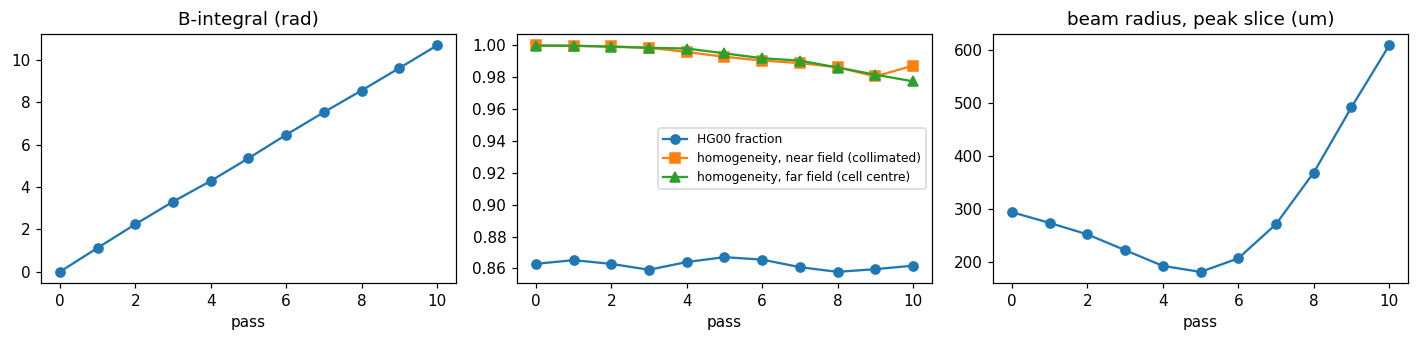

In [12]:
h = sim.history
print("recorded keys:", ", ".join(sorted(h)))
P = np.array(h["pass"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(P, h["B"], "o-"); ax[0].set_title("B-integral (rad)")
ax[1].plot(P, h["eta00_total"], "o-", label="HG00 fraction")
ax[1].plot(P, h["V_near"], "s-", label="homogeneity, near field (collimated)")
ax[1].plot(P, h["V_far"], "^-", label="homogeneity, far field (cell centre)"); ax[1].legend(fontsize=8)
ax[2].plot(P, np.array(h["w_peak_x"]) * 1e6, "o-"); ax[2].set_title("beam radius, peak slice (um)")
for a in ax: a.set_xlabel("pass")
plt.tight_layout()

### 8.2 Spectra and spatio-spectral traces

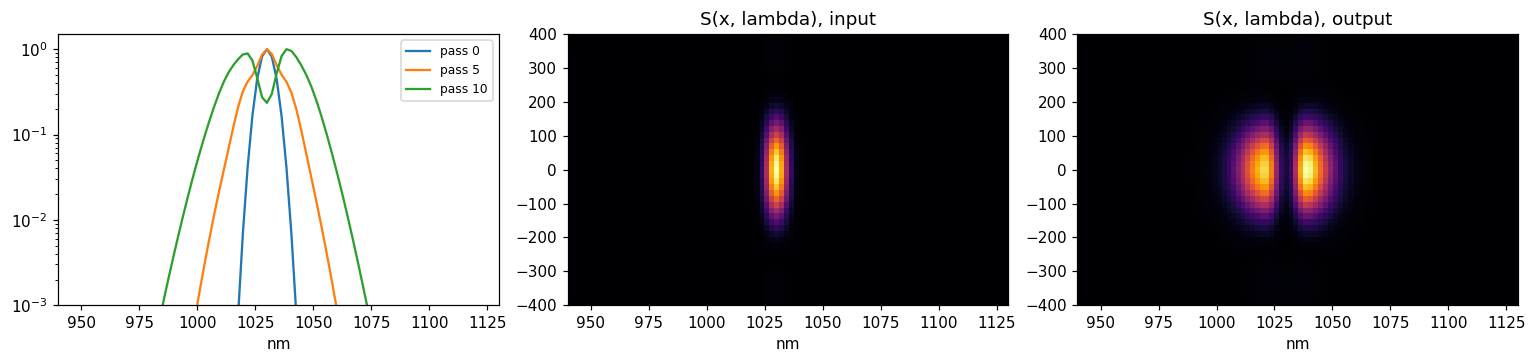

In [13]:
lam = sim.lam
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for k in (0, len(P) // 2, len(P) - 1):
    S = h["spectrum"][k]
    ax[0].semilogy(lam * 1e9, S / S.max(), label=f"pass {P[k]}")
ax[0].set_ylim(1e-3, 1.5); ax[0].set_xlim(940, 1130); ax[0].set_xlabel("nm"); ax[0].legend(fontsize=8)
for a, k, t in ((ax[1], 0, "input"), (ax[2], -1, "output")):
    S = h["sgram_x"][k]
    a.pcolormesh(lam * 1e9, sim.x * 1e6, S / S.max(), shading="auto", cmap="inferno")
    a.set_xlim(940, 1130); a.set_ylim(-400, 400); a.set_title(f"S(x, lambda), {t}"); a.set_xlabel("nm")
plt.tight_layout()

### 8.3 Beam profiles of individual colours
At the cell centre (far field) and in the collimated beam (near field).

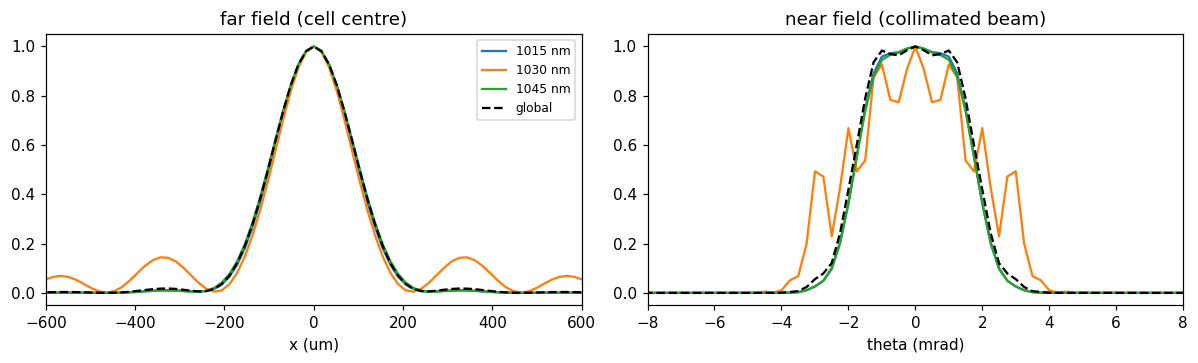

In [14]:
labels = ["1015 nm", "1030 nm", "1045 nm", "global"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, lab in enumerate(labels):
    for a, key, coord in ((ax[0], "prof_far", sim.prof_coord * 1e6), (ax[1], "prof_near", sim.theta * 1e3)):
        y = np.array(h[key][-1][i], float)
        a.plot(coord, y / y.max(), "k--" if lab == "global" else "-", label=lab)
ax[0].set_xlim(-600, 600); ax[0].set_xlabel("x (um)"); ax[0].set_title("far field (cell centre)")
ax[1].set_xlim(-8, 8); ax[1].set_xlabel("theta (mrad)"); ax[1].set_title("near field (collimated beam)"); ax[0].legend(fontsize=8)
plt.tight_layout()

### 8.4 What the mirrors see
Mirror records (`fluence_mirror`, `prof_mirror`) are taken just before each bounce, in **frame coordinates**. Convert them with `sim.mirror_scale`: $x = s_m\,\xi$ and $F = F_\text{frame}/s_m^2$. The peak fluence is what to compare with the damage threshold of the coatings.

mirror scale s_m = 6.39; max fluence 0.071 J/cm^2


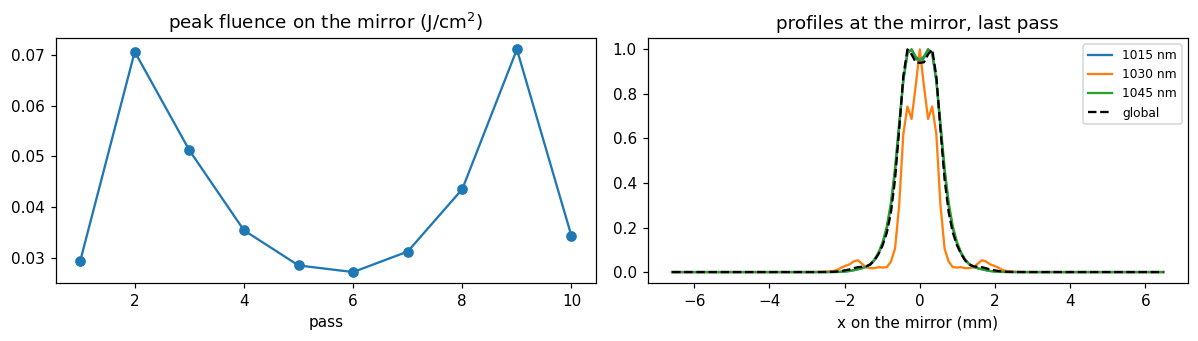

In [15]:
s = sim.mirror_scale
Fm = [f for f in h["fluence_mirror"] if f is not None]
F_peak = [f.max() / s ** 2 * 1e-4 for f in Fm]                 # J/cm^2, physical
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(P[1:], F_peak, "o-"); ax[0].set_xlabel("pass"); ax[0].set_title("peak fluence on the mirror (J/cm$^2$)")
for i, lab in enumerate(labels):
    y = np.array(h["prof_mirror"][-1][i], float)
    ax[1].plot(sim.prof_coord * s * 1e3, y / y.max(), "k--" if lab == "global" else "-", label=lab)
ax[1].set_xlabel("x on the mirror (mm)"); ax[1].set_title("profiles at the mirror, last pass"); ax[1].legend(fontsize=8)
plt.tight_layout()
print(f"mirror scale s_m = {s:.2f}; max fluence {max(F_peak):.3f} J/cm^2")

### 8.5 Compression, chirp map, modal content

compressed: 56.7 fs with -2240 fs^2 (transform limit 52.9 fs)


LG content [p, l] (l = -1, 0, 1):
 [[0.     0.8617 0.    ]
 [0.     0.0062 0.    ]]


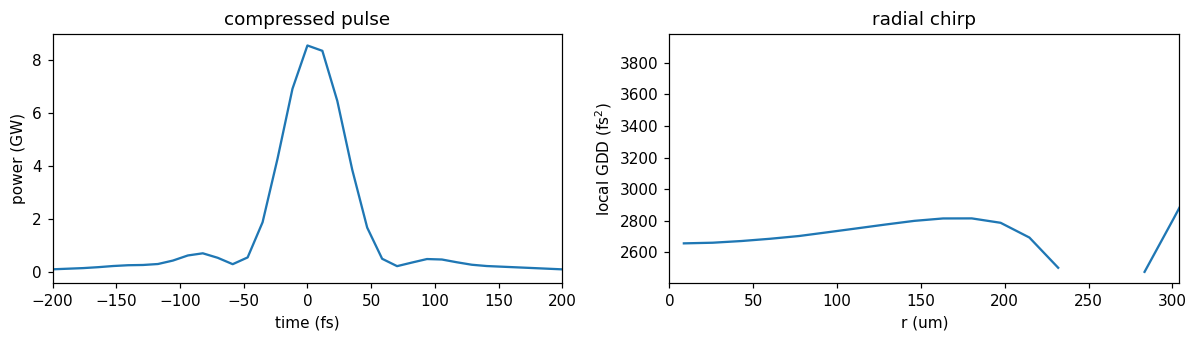

In [16]:
c = dg.compress(grid, sim.Aw)
print(f"compressed: {c['fwhm_fs']:.1f} fs with {c['gdd_fs2']:.0f} fs^2 (transform limit {c['tl_fwhm_fs']:.1f} fs)")

gdd = dg.local_gdd_map(grid, sim.Aw)
r, g = dg.radial_profile(grid, gdd)
lg = dg.lg_mode_content(grid, sim.Aw, lambda l: mm["w0"] * np.sqrt(l / 1030e-9), p_max=1, l_max=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(c["t_fs"], c["P"] / 1e9); ax[0].set_xlim(-200, 200)
ax[0].set_xlabel("time (fs)"); ax[0].set_ylabel("power (GW)"); ax[0].set_title("compressed pulse")
ax[1].plot(r * 1e6, g); ax[1].set_xlim(0, 2 * mm["w0"] * 1e6)
ax[1].set_xlabel("r (um)"); ax[1].set_ylabel("local GDD (fs$^2$)"); ax[1].set_title("radial chirp")
plt.tight_layout()
print("LG content [p, l] (l = -1, 0, 1):\n", np.round(lg["frac"], 4))

## 9. Saving, checkpoints and the GPU

* `sim.save("run.npz")` writes the history, axes and metadata (and the final field) as NumPy arrays.
* `sim.checkpoint(path)` / `sim.resume(path)` and `sim.run(max_seconds=...)` split long runs.
* Everything returned by the diagnostics is a NumPy array, whether the run used the CPU or the GPU. `th.to_host(sim.Aw)` gives the field itself.

In [17]:
sim.save("tutorial_run.npz", include_field=False)
with np.load("tutorial_run.npz") as d:      # closed before the file is removed (needed on Windows)
    print("saved:", ", ".join(sorted(d.files))[:300], "...")
os.remove("tutorial_run.npz")

saved: B, M2x, M2x_mean, M2y, M2y_mean, R, V_far, V_near, band_energy, d, energy, eta00, eta00_total, fluence, fluence_mirror, gas, grid, lam, lambda0, n2, n_passes, order_frac, pass, peak_power, pressure_bar, prof_bandwidth, prof_coord, prof_far, prof_far_proj, prof_mirror, prof_near, prof_wavelengths, sg ...


### Running on a GPU
With an NVIDIA GPU and CuPy installed (`uv pip install cupy-cuda12x`; RTX 50-series cards need CUDA ≥ 12.8), `device="auto"` already uses it. The cell below times one pass on each available device for the same problem.

In [18]:
def time_one_pass(device):
    g = th.suggest_lens_grid(cell, 1030e-9, 900e-9, 1200e-9, 200e-15, box_factor=12, device=device)
    E = th.gaussian_spectrum(g, fwhm_fs=200)
    p = th.Pulse.at_focus(g, E, th.Beam(th.gaussian(mm["w0"])), 0.6e-3)
    s = th.LensFrameSimulation(p, cell, phi_max=0.02, near_field=False, record_mirror=False)
    t0 = time.time(); s.run(n_passes=1, verbose=False)
    return time.time() - t0

print(f"CPU: {time_one_pass('cpu'):.1f} s per pass")
if th.gpu_available():
    time_one_pass("gpu")                                  # first call compiles the GPU kernels
    print(f"GPU: {time_one_pass('gpu'):.2f} s per pass")
else:
    print("no GPU found: install CuPy to compare")

CPU: 13.9 s per pass
no GPU found: install CuPy to compare


## Exercises

1. **Mode mismatch**: inject the *linear* waist `cell.linear_mode(1030e-9)["w0"]` instead of `mm["w0"]` with `Pulse.at_focus` and plot `w_peak_x` versus pass: the beam breathes around the Kerr-matched size.
2. **Top-hat cleaning**: run the two top-hat inputs of section 6 and compare `eta00_total`, `V_near` and the per-colour profiles with the matched Gaussian.
3. **Donut mode**: replace the Gaussian with `th.laguerre_gauss(mm["w0"], 0, 1)` and follow `dg.lg_mode_content` pass after pass.
4. **Space-time couplings**: add a pulse-front tilt (`pft_fs_per_mm=(2, 0)`) and see how it evolves in `sgram_theta`.
5. **Convergence**: rerun with `phi_max=0.01`, then with `gouy_step=0.025` and a larger `points_per_waist`, and compare the output spectrum.
6. **Closer to the stability edge**: move the cell towards $d \to 2R$ (e.g. `MPC(R=0.5, d=0.995, ...)`): `s_m` grows, the mirror spot grows, but the lens-frame grid barely changes.